# 04 · Validation, scope check and fair lending follow-up

In [1]:
import sys; sys.path.insert(0, "../src")
from mu_catiii import *
from plots import *
pd.set_option("display.width", 160)
dev, mon, pd_old, lgd, ead = load_inputs()
pooled = pd.concat([dev, mon], ignore_index=True)
term_by_segment = pooled.groupby("segment")["term_months"].max().to_dict()

## 1. Out-of-sample validation
Recalibrating on **all** the evidence leaves no independent period to test on. So 20% of the pooled loans (stratified by pool) are set aside **before** fitting and the model is re-estimated on the other 80%.

*Limit that matters:* this is out-of-**sample**, not out-of-**time**. It shows the fit is not memorising rows. It does not prove the model will hold in conditions that have not happened yet; only time does, hence the reinforced monitoring condition.

In [2]:
h = pd.read_csv(TABLES / '04_holdout_validation.csv'); display(h.T)
display(pd.read_csv(TABLES / '04_holdout_calibration_by_pool.csv'))

,0
holdout_loans,"6,000.0000"
AUC,0.7165
Gini,0.4331
KS,0.3623
AE_aggregate,1.0013
AE_low,0.9226
AE_high,1.0832


,pool_id,rate_train,rate_holdout,n_holdout,AE_ratio
0,auto_loan | near-prime(640-679),0.1080,0.0879,398,0.8145
1,auto_loan | prime(680-719),0.0639,0.0503,517,0.7875
2,auto_loan | subprime(<640),0.2092,0.2375,240,1.1355
3,auto_loan | super-prime(720+),0.0303,0.0153,652,0.5069
4,credit_card | near-prime(640-679),0.0949,0.1307,398,1.3766
5,credit_card | prime(680-719),0.0605,0.0581,499,0.9601
6,credit_card | subprime(<640),0.2082,0.2090,244,1.0039
7,credit_card | super-prime(720+),0.0275,0.0251,637,0.9143
8,heloc | near-prime(640-679),0.1143,0.1316,190,1.1509
9,heloc | prime(680-719),0.0580,0.0472,254,0.8144


Note the A/E sampling range [0.92, 1.08]: an aggregate A/E of 1.00 is a clean result, but this holdout could not have distinguished an error of ±8%. The comparison is raw rate against raw rate over comparable windows. (Comparing a raw rate with a *lifetime* PD would mix different horizons, so it is not done.)

## 2. Scope check: did LGD or EAD move too?
The Model Update was scoped to PD because the monitoring finding was about default rates. Before signing off a PD-only scope it is worth testing that nothing else moved.

In [3]:
display(pd.read_csv(TABLES / '04_scope_test_lgd.csv'))
display(pd.read_csv(TABLES / '04_scope_test_ead.csv'))

,segment,defaults_dev,defaults_mon,LGD_table_avg,LGD_realized_dev,LGD_realized_mon,diff_mon_minus_dev,p_value
0,auto_loan,432,280,0.4250,0.4247,0.4330,0.0082,0.3881
1,personal_loan,366,226,0.8195,0.7922,0.7971,0.0048,0.6185
2,credit_card,423,270,0.8970,0.8717,0.8643,-0.0074,0.3647
3,heloc,243,137,0.2865,0.2994,0.3576,0.0582,0.0000


,segment,measure,n_dev,n_mon,mean_dev,mean_mon,diff,p_value
0,auto_loan,ead_ratio_realized,432,280,0.7636,0.7746,0.0110,0.2135
1,personal_loan,ead_ratio_realized,366,226,0.5942,0.6336,0.0394,0.0141
2,credit_card,ccf_realized,423,270,0.5570,0.5435,-0.0135,0.4924
3,heloc,ccf_realized,243,137,0.7109,0.6692,-0.0417,0.0779


**Finding: HELOC realized LGD rose from 0.30 to 0.36 (p < 0.0001).** The other three products did not move. The HPI fell from +4.0% to +1.0% in the same window, which is the collateral channel one would expect. By origination half-year:

In [4]:
display(pd.read_csv(TABLES / '04_heloc_lgd_by_vintage.csv'))

,half,defaults,lgd_realized
0,2022H1,97,0.2955
1,2022H2,82,0.3007
2,2023H1,64,0.3036
3,2023H2,81,0.3742
4,2024H1,56,0.3337


A break at the 2023H2 vintage, not a drift. Caveat: monitoring loans have had less time for recoveries to arrive, which could bias LGD upward; but the same shorter window did not move the other three products, which argues against a pure artifact. What it would do to the answer:

In [5]:
display(pd.read_csv(TABLES / '04_scope_scenario_heloc_lgd.csv'))

,scenario,EL,change_vs_production,above_10pct_threshold
0,PD recalibration only (the Model Update scope),"20,733,968.4016",0.0464,False
1,"HELOC LGD only, pooled evidence","20,353,257.6739",0.0272,False
2,"PD recalibration + HELOC LGD, pooled evidence","21,274,239.2430",0.0737,False
3,"HELOC LGD only, monitoring regime persists","21,310,108.6675",0.0755,False
4,"PD recalibration + HELOC LGD, monitoring regime persists","22,232,529.8596",0.1221,True


**Two readings of the same forecast question.** If HELOC LGD is re-estimated on pooled evidence (the same logic as the PD update), the combined change is **+7.4%**. If the monitoring-period LGD persists, it is **+12.2%**. The range straddles the 10% threshold. Changes should not be split to stay under a materiality line, so the report recommends assessing the PD and LGD items **together**, applying the policy's borderline rule, and treating the package as potentially material until the linked HELOC LGD review concludes.

## 3. Fair lending follow-up
A synthetic BISG-style proxy (never a model input) is used to compute an **Adverse Impact Ratio**: approval rate of the protected-proxy group ÷ approval rate of the reference group, with approval defined as lifetime PD at or below the portfolio median. Internal scale [JUDGMENT]: ≥ 0.90 green, 0.80 to 0.90 amber, < 0.80 red.

,AIR_production,AIR_recalibrated,AIR_production_within_product,AIR_recalibrated_within_product,share_below_portfolio_median,status_production,status_recalibrated
all,0.8138,0.8138,0.8387,0.8387,NaN,AMBER,AMBER
auto_loan,0.8360,0.8360,0.8360,0.8360,0.6519,AMBER,AMBER
personal_loan,0.8376,0.8376,0.8376,0.8376,0.6404,AMBER,AMBER
credit_card,0.7342,0.7342,0.8479,0.8479,0.3582,RED,RED
heloc,0.8284,0.8284,0.8284,0.8284,0.6431,AMBER,AMBER


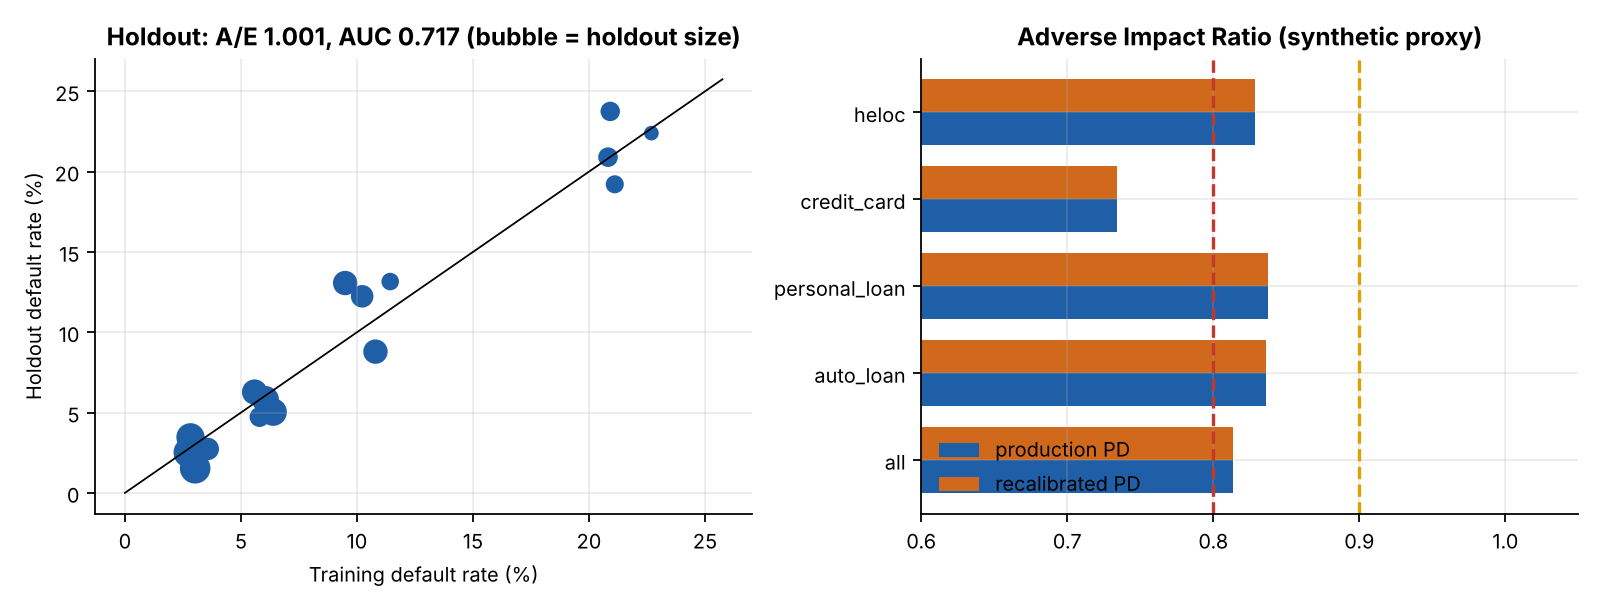

In [6]:
air = pd.read_csv(TABLES / '04_adverse_impact_ratio.csv', index_col=0); display(air)
show_image(FIGS / 'fig10_holdout_and_air.png')

The recalibration leaves AIR unchanged at this precision: the update shifts levels, not the ordering of loans around the median that defines approval. The credit-card result (red, 0.73) is **an artifact of the cut-off rule, not a finding**: one portfolio-wide median leaves only 36% of cards under the cut-off, against about 65% for the other products, because cards carry higher PDs. With a cut-off inside each product the card AIR is 0.85, in line with the others (columns `*_within_product`).

Regulatory framing (see decision log): since the CFPB's April 2026 final rule (effective July 21, 2026), Regulation B no longer treats ECOA as providing a disparate-impact test, but proxy-based disparate **treatment** remains prohibited, and the Fair Housing Act (relevant to HELOC) continues to be read to cover disparate impact (*Inclusive Communities*, 2015). AIR is used here as an internal governance indicator, not as a legal test.